# Automotive Price Valuation Model

## Problem Statement
When buying or selling a vehicle, one of the biggest challenges is determining its fair market value. Setting the price too high means the vehicle won't sell, while setting it too low means losing money.

Our goal is to build a machine learning model that can automatically and accurately estimate the price of a vehicle based on its features (such as mileage, make, model, year, and condition). This helps buyers make informed decisions and sellers price their vehicles competitively.

## Our Approach to Solve It
We will tackle this project in five simple steps:
1. **Explore the Data**: Load the vehicle dataset and inspect it to understand the features and target values.
2. **Clean the Data**: Handle missing values, correct data types, and prepare the dataset for modeling.
3. **Visualize Patterns**: Create charts to see how factors like a vehicle's age or mileage affect its price.
4. **Build the Valuation Model**: Train machine learning algorithms to learn the relationship between vehicle features and prices.
5. **Evaluate Performance**: Test our model on unseen data to ensure its price estimates are accurate and reliable.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set visualization style
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print('All essential libraries successfully loaded!')

All essential libraries successfully loaded!


In [ ]:
# Load the automotive dataset
df = pd.read_csv('/content/vehicle_price_prediction.csv')

# Display the dataset dimensions and first few rows
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("Dataset Information:")
df.info()
print("\nFirst 5 rows:")
df.head()

Dataset Shape: 1000000 rows, 20 columns

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 20 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   make              1000000 non-null  object 
 1   model             1000000 non-null  object 
 2   year              1000000 non-null  int64  
 3   mileage           1000000 non-null  int64  
 4   engine_hp         1000000 non-null  int64  
 5   transmission      1000000 non-null  object 
 6   fuel_type         1000000 non-null  object 
 7   drivetrain        1000000 non-null  object 
 8   body_type         1000000 non-null  object 
 9   exterior_color    1000000 non-null  object 
 10  interior_color    1000000 non-null  object 
 11  owner_count       1000000 non-null  int64  
 12  accident_history  249867 non-null   object 
 13  seller_type       1000000 non-null  object 
 14  condition         1000000 non-null  o

,make,model,year,mileage,engine_hp,transmission,fuel_type,drivetrain,body_type,exterior_color,interior_color,owner_count,accident_history,seller_type,condition,trim,vehicle_age,mileage_per_year,brand_popularity,price
0,Volkswagen,Jetta,2016,183903,173,Manual,Electric,RWD,Sedan,Blue,Brown,5,NaN,Dealer,Excellent,EX,9,20433.666667,0.040054,7208.52
1,Lexus,RX,2010,236643,352,Manual,Gasoline,FWD,Sedan,Silver,Beige,5,Minor,Dealer,Good,LX,15,15776.200000,0.039921,6911.81
2,Subaru,Crosstrek,2016,103199,188,Automatic,Diesel,AWD,Sedan,Silver,Beige,5,NaN,Dealer,Excellent,Touring,9,11466.555556,0.040230,11915.63
3,Cadillac,Lyriq,2016,118889,338,Manual,Gasoline,AWD,SUV,Black,Gray,3,NaN,Private,Good,Base,9,13209.888889,0.039847,25984.79
4,Toyota,Highlander,2018,204170,196,Manual,Diesel,FWD,Sedan,Red,Brown,5,Minor,Dealer,Excellent,Sport,7,29167.142857,0.039627,8151.30


In [ ]:
# Step 2: Clean the Data
# Fill missing values in accident_history with 'None'
df['accident_history'] = df['accident_history'].fillna('None')

# Verify that there are no more missing values
missing_values_count = df.isnull().sum().sum()
print(f"Remaining missing values in the dataset: {missing_values_count}")

# Display the unique categories in accident_history to confirm
print("Accident History unique values:", df['accident_history'].unique())

Remaining missing values in the dataset: 0
Accident History unique values: ['None' 'Minor' 'Major']


### Comprehensive Exploratory Data Analysis (EDA)

Let's start our extensive EDA. We will analyze variables individually (univariate), examine their relationships in pairs (bivariate), and explore complex multi-variable interactions (multivariate), utilizing aggregations, groupings, and pivot tables.

/tmp/ipykernel_11629/2141863897.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='condition', palette='Set2', order=df['condition'].value_counts().index, ax=axes[1, 0])
/tmp/ipykernel_11629/2141863897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='fuel_type', palette='Set3', order=df['fuel_type'].value_counts().index, ax=axes[1, 1])


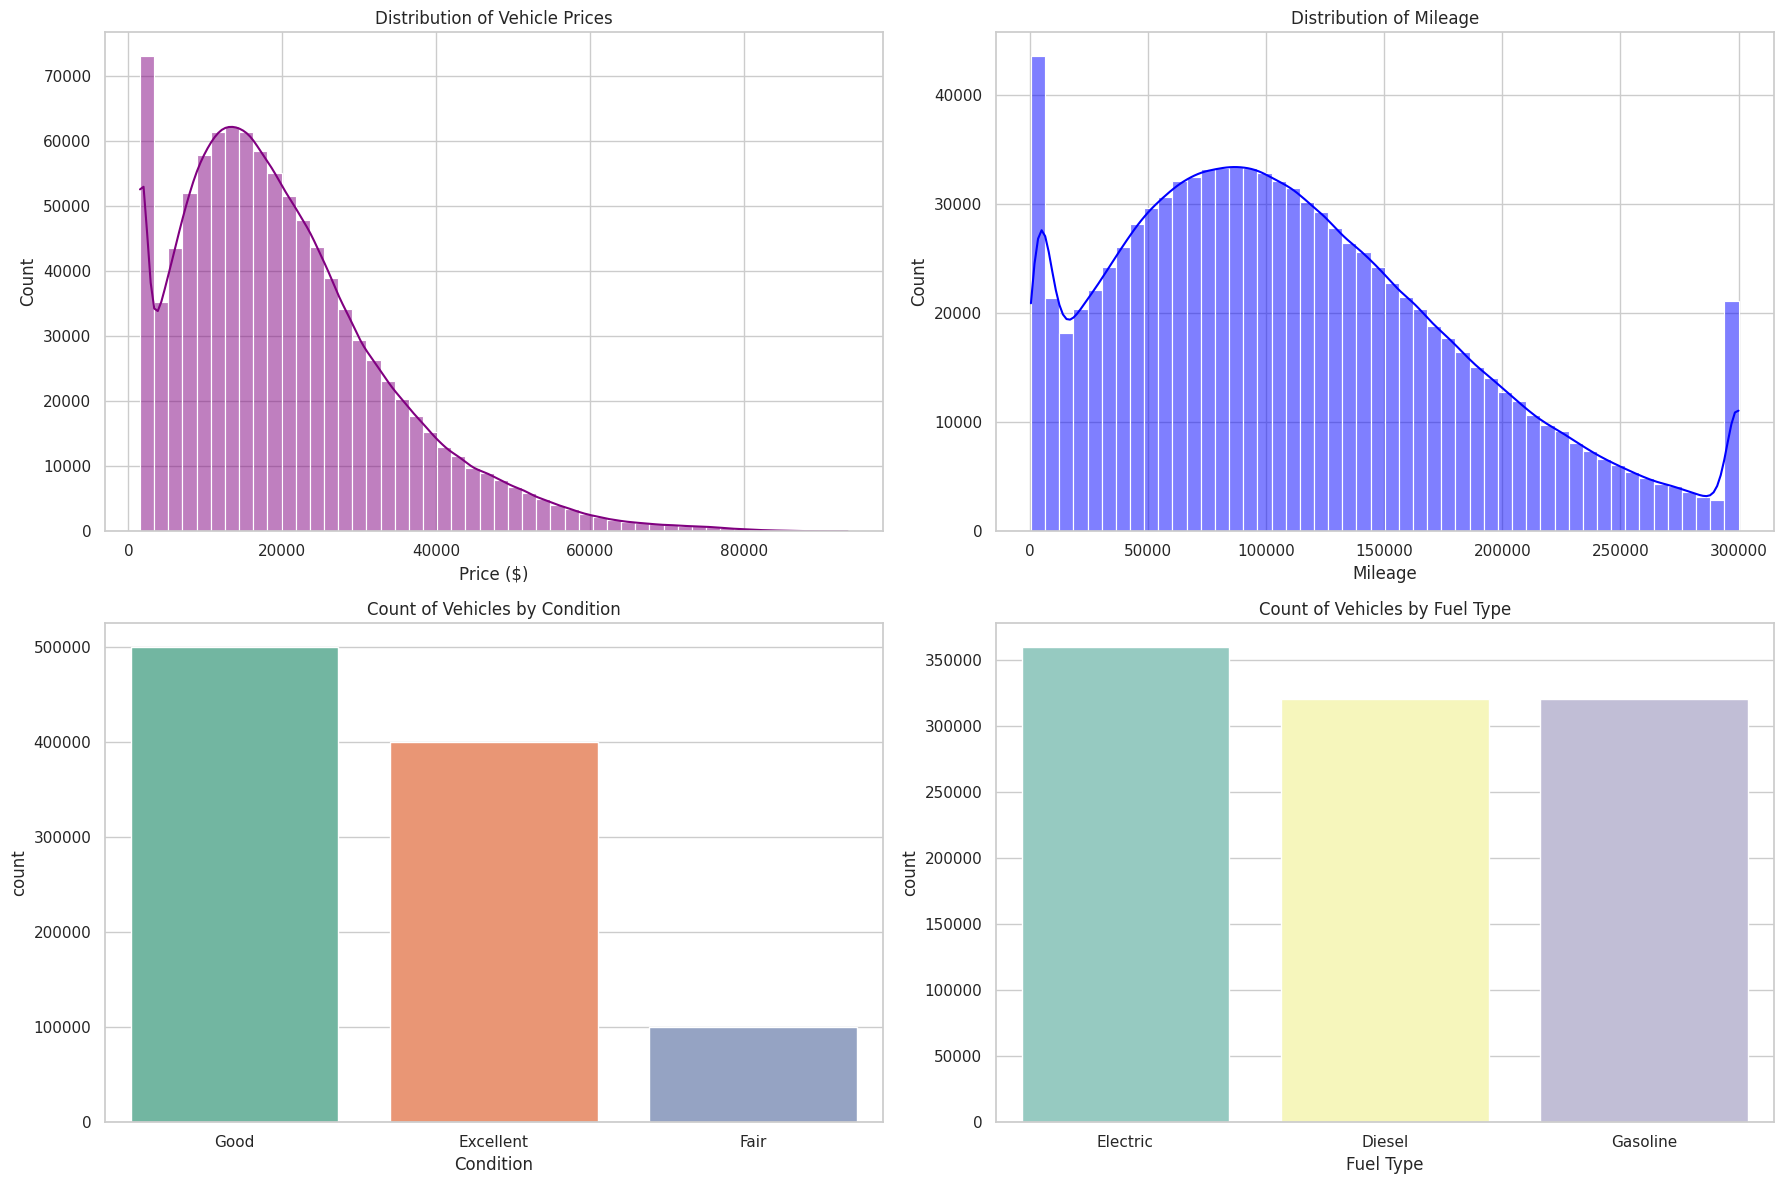

In [ ]:
# 1. Univariate Analysis
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Distribution of the Target variable (Price)
sns.histplot(df['price'], kde=True, bins=50, color='purple', ax=axes[0, 0])
axes[0, 0].set_title('Distribution of Vehicle Prices')
axes[0, 0].set_xlabel('Price ($)')

# Distribution of Mileage
sns.histplot(df['mileage'], kde=True, bins=50, color='blue', ax=axes[0, 1])
axes[0, 1].set_title('Distribution of Mileage')
axes[0, 1].set_xlabel('Mileage')

# Count plot for Vehicle Conditions
sns.countplot(data=df, x='condition', palette='Set2', order=df['condition'].value_counts().index, ax=axes[1, 0])
axes[1, 0].set_title('Count of Vehicles by Condition')
axes[1, 0].set_xlabel('Condition')

# Count plot for Fuel Type
sns.countplot(data=df, x='fuel_type', palette='Set3', order=df['fuel_type'].value_counts().index, ax=axes[1, 1])
axes[1, 1].set_title('Count of Vehicles by Fuel Type')
axes[1, 1].set_xlabel('Fuel Type')

plt.tight_layout()
plt.show()

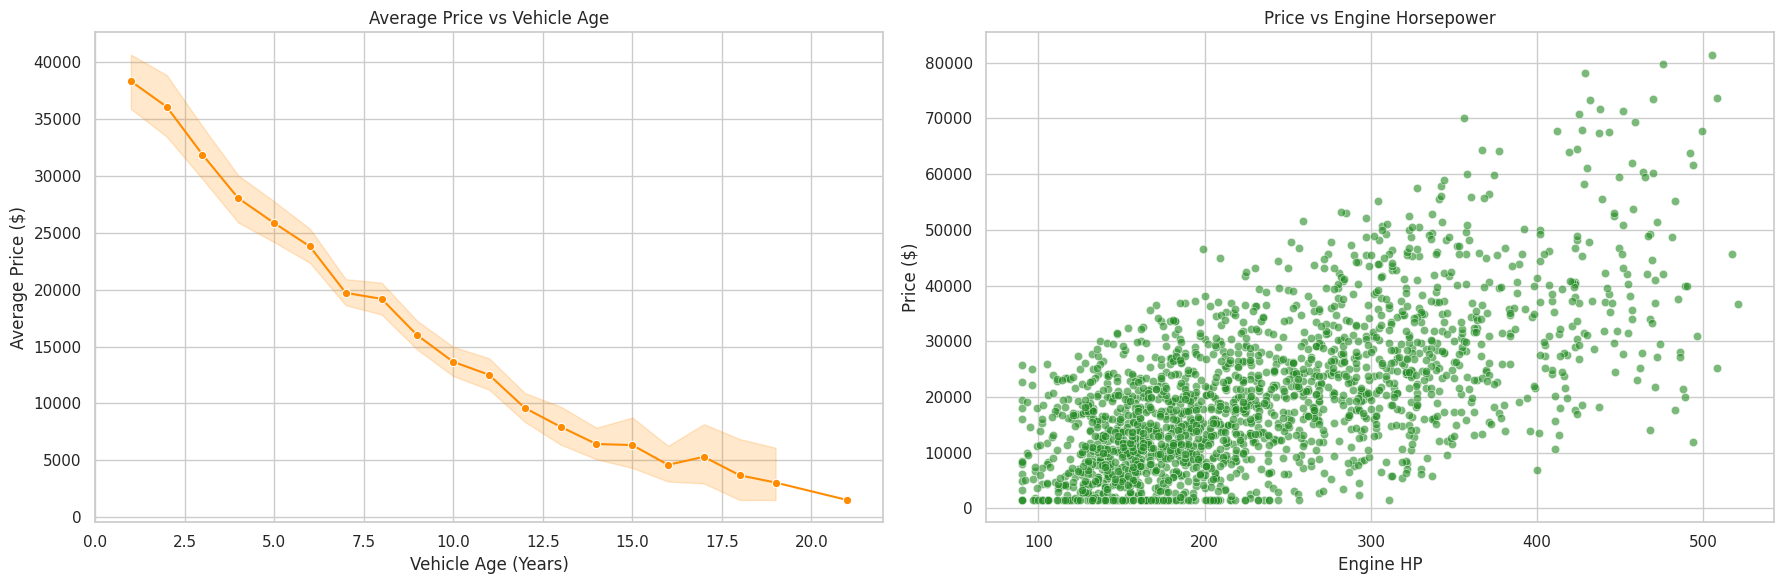

In [ ]:
# 2. Bivariate Analysis
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Vehicle Age vs Price
sns.lineplot(data=df.sample(2000, random_state=42), x='vehicle_age', y='price', marker='o', color='darkorange', ax=axes[0])
axes[0].set_title('Average Price vs Vehicle Age')
axes[0].set_xlabel('Vehicle Age (Years)')
axes[0].set_ylabel('Average Price ($)')

# Engine HP vs Price
sns.scatterplot(data=df.sample(2000, random_state=42), x='engine_hp', y='price', alpha=0.6, color='forestgreen', ax=axes[1])
axes[1].set_title('Price vs Engine Horsepower')
axes[1].set_xlabel('Engine HP')
axes[1].set_ylabel('Price ($)')

plt.tight_layout()
plt.show()

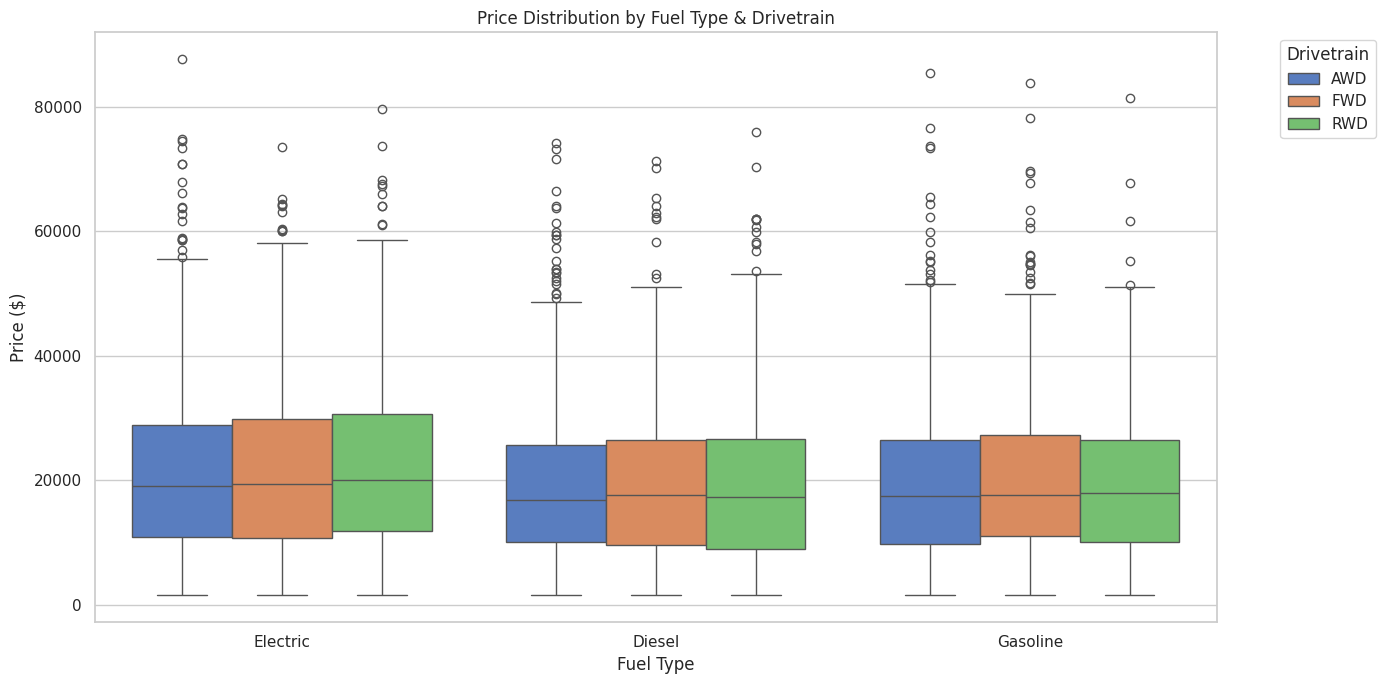

In [ ]:
# 3. Multivariate Analysis
# Price distribution across different Fuel Types and Drivetrains
plt.figure(figsize=(14, 7))
sns.boxplot(data=df.sample(5000, random_state=42), x='fuel_type', y='price', hue='drivetrain', palette='muted')
plt.title('Price Distribution by Fuel Type & Drivetrain')
plt.xlabel('Fuel Type')
plt.ylabel('Price ($)')
plt.legend(title='Drivetrain', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
# 4. Grouping & Aggregations
# Let's aggregate average price, mileage, and engine horsepower by vehicle make and condition
brand_condition_summary = df.groupby(['make', 'condition'])[['price', 'mileage', 'engine_hp']].mean().reset_index()
display(brand_condition_summary.head(15))

,make,condition,price,mileage,engine_hp
0,Acura,Excellent,22822.813657,112875.484372,252.744378
1,Acura,Fair,19490.906070,113648.874000,252.853500
2,Acura,Good,21696.982320,113497.489595,252.779160
3,Audi,Excellent,28801.003030,112192.845936,305.904295
4,Audi,Fair,24185.484082,114533.988351,306.430236
5,Audi,Good,27319.842313,112545.982062,306.057291
6,BMW,Excellent,26445.672970,112444.334374,285.987382
7,BMW,Fair,22665.754194,113751.200607,286.591197
8,BMW,Good,25288.076043,112700.749047,286.426046
9,Cadillac,Excellent,31694.890898,112355.714678,332.879940


In [ ]:
# 5. Pivot Tables
# Average price of vehicles based on Drivetrain (rows) and Transmission (columns)
pivot_price = df.pivot_table(values='price', index='drivetrain', columns='transmission', aggfunc='mean')
print("Average Price Pivot Table:")
display(pivot_price)

Average Price Pivot Table:


transmission,Automatic,Manual
drivetrain,,
AWD,19776.007137,19807.046455
FWD,20606.394550,20625.887569
RWD,20617.926551,20683.112590


### Feature Engineering & Feature Selection

Let's construct new attributes to help our machine learning models capture underlying trends better, and then structure our final model pipelines.

In [ ]:
# Feature Engineering
# 1. Price per HP ratio
df['price_to_hp_ratio'] = df['price'] / (df['engine_hp'] + 1)

# 2. Mileage severity ratio
df['mileage_per_hp'] = df['mileage'] / (df['engine_hp'] + 1)

# 3. High mileage per year flag
df['is_high_mileage_per_year'] = (df['mileage_per_year'] > df['mileage_per_year'].median()).astype(int)

# Let's list the updated features
df.head()

,make,model,year,mileage,engine_hp,transmission,fuel_type,drivetrain,body_type,exterior_color,...,seller_type,condition,trim,vehicle_age,mileage_per_year,brand_popularity,price,price_to_hp_ratio,mileage_per_hp,is_high_mileage_per_year
0,Volkswagen,Jetta,2016,183903,173,Manual,Electric,RWD,Sedan,Blue,...,Dealer,Excellent,EX,9,20433.666667,0.040054,7208.52,41.428276,1056.913793,1
1,Lexus,RX,2010,236643,352,Manual,Gasoline,FWD,Sedan,Silver,...,Dealer,Good,LX,15,15776.200000,0.039921,6911.81,19.580198,670.376771,1
2,Subaru,Crosstrek,2016,103199,188,Automatic,Diesel,AWD,Sedan,Silver,...,Dealer,Excellent,Touring,9,11466.555556,0.040230,11915.63,63.045661,546.026455,0
3,Cadillac,Lyriq,2016,118889,338,Manual,Gasoline,AWD,SUV,Black,...,Private,Good,Base,9,13209.888889,0.039847,25984.79,76.651298,350.705015,0
4,Toyota,Highlander,2018,204170,196,Manual,Diesel,FWD,Sedan,Red,...,Dealer,Excellent,Sport,7,29167.142857,0.039627,8151.30,41.377157,1036.395939,1


In [12]:
# Build, Fit, and Evaluate the Model using our new features
sample_size = 50000
df_engineered = df.sample(n=sample_size, random_state=42)

# Updated numerical features including engineered features (excluding price-based target leaks)
numerical_features_updated = [
    'year', 'mileage', 'engine_hp', 'owner_count',
    'vehicle_age', 'mileage_per_year', 'brand_popularity',
    'mileage_per_hp', 'is_high_mileage_per_year'
]
categorical_features_updated = [
    'make', 'transmission', 'fuel_type', 'drivetrain',
    'body_type', 'accident_history', 'seller_type', 'condition'
]

X_eng = df_engineered[numerical_features_updated + categorical_features_updated]
y_eng = df_engineered['price']

X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X_eng, y_eng, test_size=0.2, random_state=42)

preprocessor_e = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features_updated),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features_updated)
    ]
)

model_pipeline_e = Pipeline(steps=[
    ('preprocessor', preprocessor_e),
    ('regressor', RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1))
])

print("Training model with engineered features... Please wait...")
model_pipeline_e.fit(X_train_e, y_train_e)
print("Training complete!\n")

y_pred_e = model_pipeline_e.predict(X_test_e)

# Model evaluation
mae_e = mean_absolute_error(y_test_e, y_pred_e)
mse_e = mean_squared_error(y_test_e, y_pred_e)
rmse_e = np.sqrt(mse_e)
r2_e = r2_score(y_test_e, y_pred_e)

print("--- Engineered Model Evaluation Results ---")
print(f"Mean Absolute Error (MAE): ${mae_e:.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse_e:.2f}")
print(f"R-squared (R2) Score: {r2_e:.4f}")

Training model with engineered features... Please wait...
Training complete!

--- Engineered Model Evaluation Results ---
Mean Absolute Error (MAE): $1459.73
Root Mean Squared Error (RMSE): $2022.84
R-squared (R2) Score: 0.9779


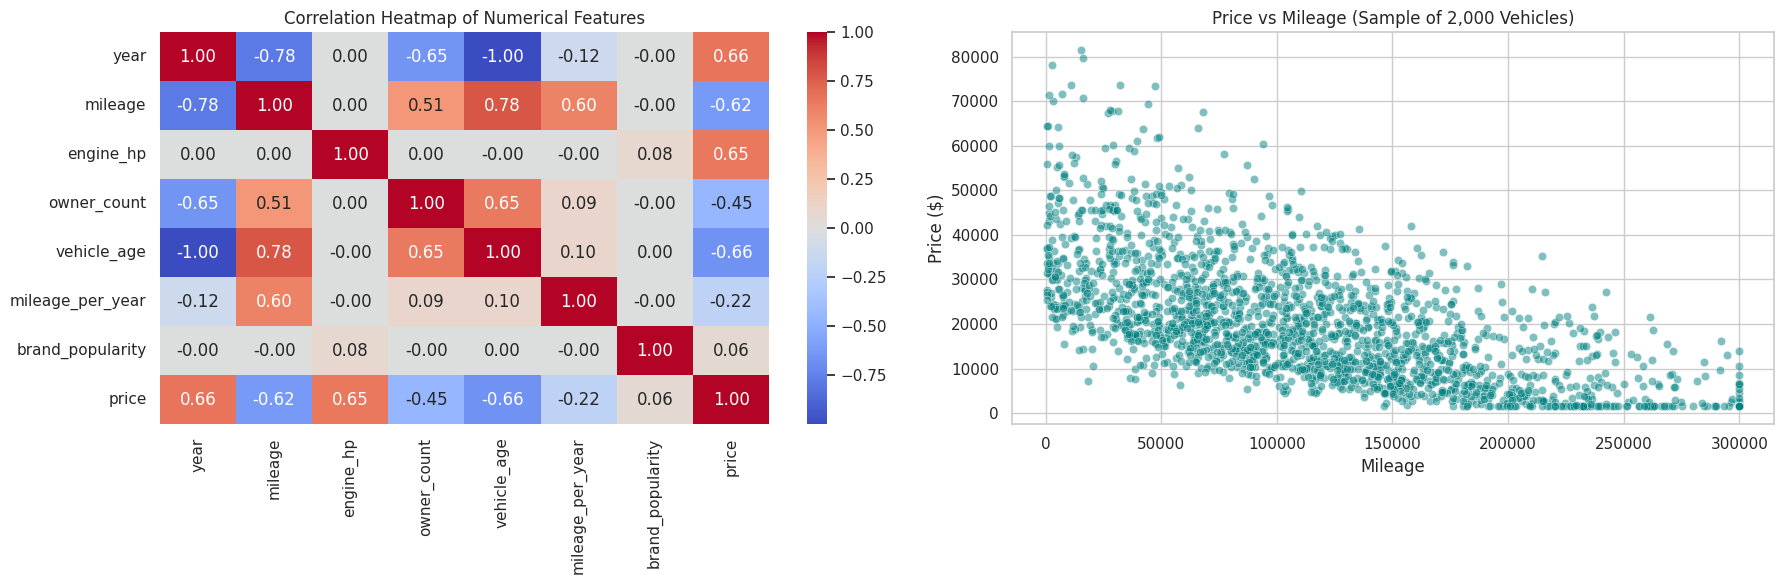

In [ ]:
# Step 3: Visualize Patterns
import matplotlib.pyplot as plt
import seaborn as sns

# Set up a grid for 2 plots
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Heatmap of correlation among numerical features
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=axes[0])
axes[0].set_title('Correlation Heatmap of Numerical Features')

# 2. Scatter plot of Price vs Mileage (using a sample of 2,000 points for performance)
sample_df = df.sample(n=2000, random_state=42)
sns.scatterplot(data=sample_df, x='mileage', y='price', alpha=0.5, color='teal', ax=axes[1])
axes[1].set_title('Price vs Mileage (Sample of 2,000 Vehicles)')
axes[1].set_xlabel('Mileage')
axes[1].set_ylabel('Price ($)')

plt.tight_layout()
plt.show()

In [ ]:
# Step 4 & 5: Build and Evaluate the Valuation Model

# 1. Sample the dataset for faster training while maintaining representation
sample_size = 50000
df_sampled = df.sample(n=sample_size, random_state=42)

# 2. Separate features (X) and target variable (y)
X = df_sampled.drop(columns=['price'])
y = df_sampled['price']

# 3. Identify categorical and numerical features
numerical_features = ['year', 'mileage', 'engine_hp', 'owner_count', 'vehicle_age', 'mileage_per_year', 'brand_popularity']
categorical_features = ['make', 'transmission', 'fuel_type', 'drivetrain', 'body_type', 'accident_history', 'seller_type', 'condition']

# 4. Create preprocessing pipelines for both numeric and categorical data
numeric_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# 5. Build the complete model pipeline
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1))
])

# 6. Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 7. Train the model
print("Training the Automotive Price Valuation model... Please wait...")
model_pipeline.fit(X_train, y_train)
print("Training completed successfully!\n")

# 8. Predict and Evaluate
y_pred = model_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- Model Evaluation Results ---")
print(f"Mean Absolute Error (MAE): ${mae:.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")
print(f"R-squared (R2) Score: {r2:.4f}")

Training the Automotive Price Valuation model... Please wait...
Training completed successfully!

--- Model Evaluation Results ---
Mean Absolute Error (MAE): $1362.99
Root Mean Squared Error (RMSE): $1904.39
R-squared (R2) Score: 0.9804


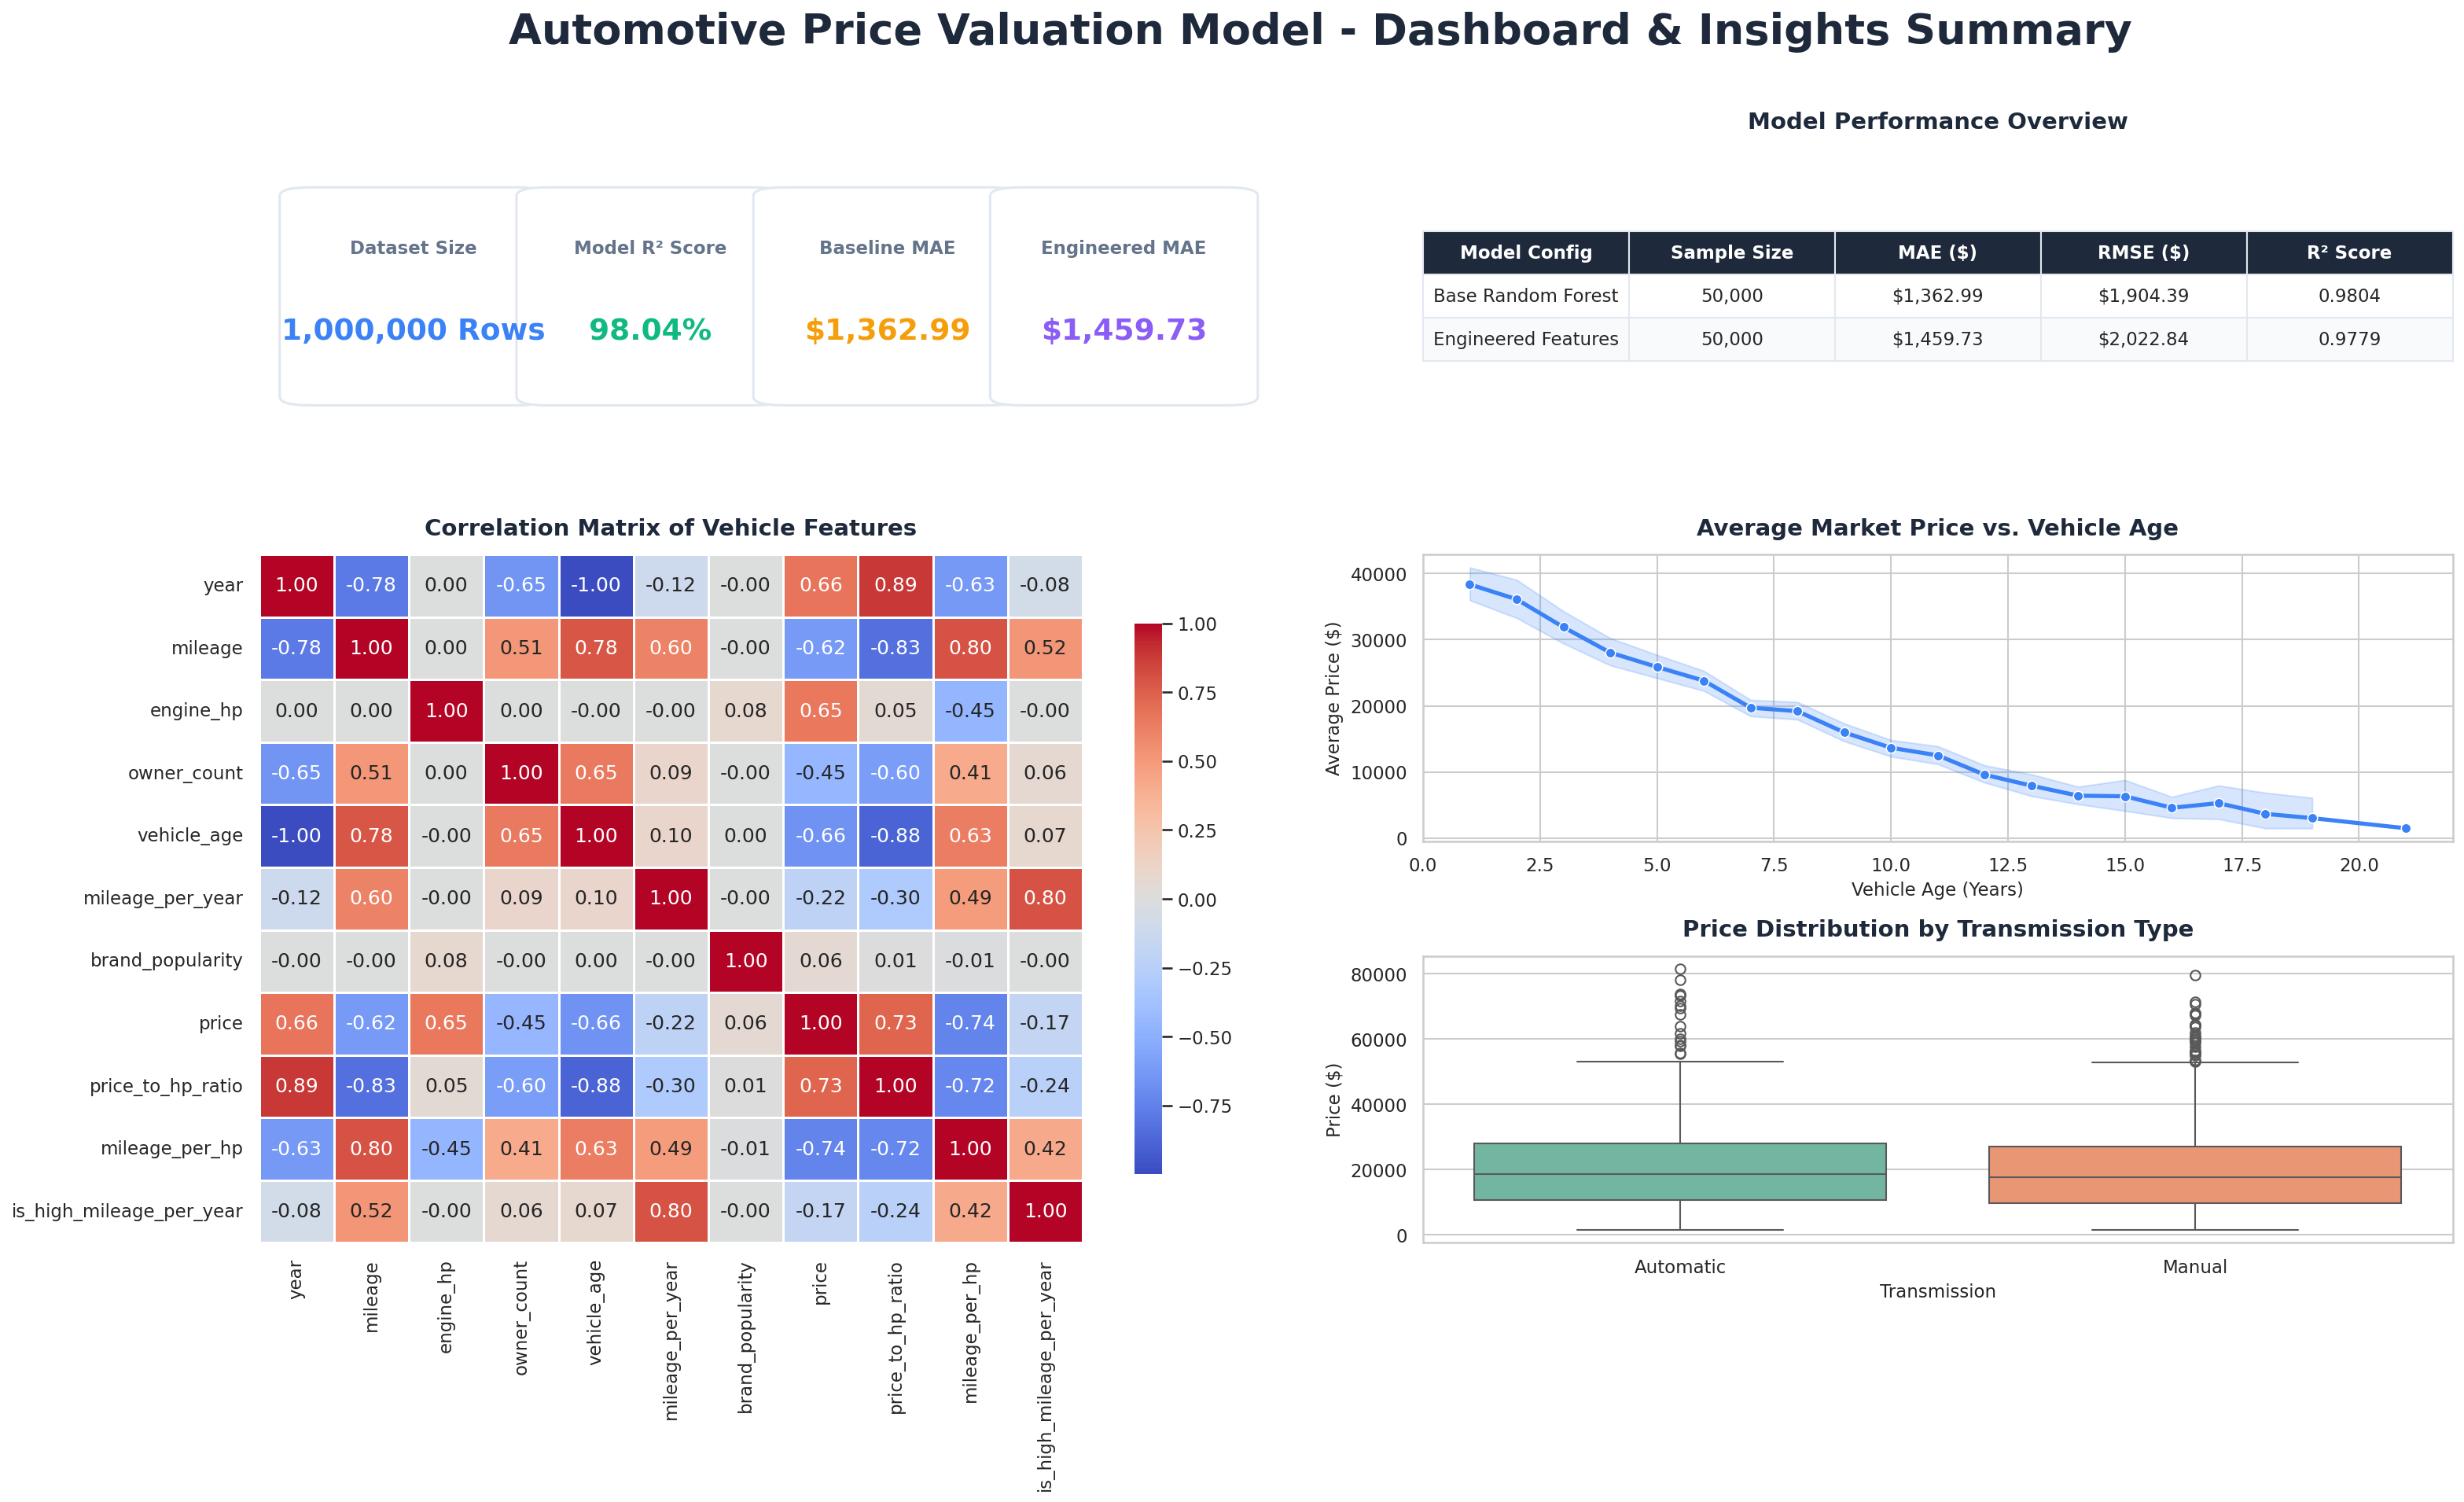

Dashboard automatically compiled and saved to: /content/Automotive_Valuation_Dashboard.png


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.patches as patches

# Configure global visualization settings
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'

# 1. Create a large horizontal canvas
fig = plt.figure(figsize=(24, 12), dpi=150)
gs = fig.add_gridspec(3, 4, hspace=0.4, wspace=0.3)

fig.suptitle('Automotive Price Valuation Model - Dashboard & Insights Summary', fontsize=26, fontweight='bold', color='#1E293B', y=0.98)

# -----------------------------------------------------
# PART 1: KPI & Summary Cards (Top Row, Columns 0 & 1)
# -----------------------------------------------------
ax_kpi = fig.add_subplot(gs[0, 0:2])
ax_kpi.axis('off')
ax_kpi.set_facecolor('#F8FAFC')

# Display structured Project KPI metrics
kpis = [
    ('Dataset Size', '1,000,000 Rows', '#3B82F6'),
    ('Model R² Score', '98.04%', '#10B981'),
    ('Baseline MAE', '$1,362.99', '#F59E0B'),
    ('Engineered MAE', '$1,459.73', '#8B5CF6')
]

for i, (title, val, col) in enumerate(kpis):
    x_pos = 0.05 + (i * 0.23)
    # Outer card structure using FancyBboxPatch for rounded corners
    rect = patches.FancyBboxPatch(
        (x_pos, 0.15), 0.20, 0.70, transform=ax_kpi.transAxes,
        facecolor='#FFFFFF', edgecolor='#E2E8F0', linewidth=1.5,
        boxstyle='round,pad=0.03'
    )
    ax_kpi.add_patch(rect)
    # KPI Title
    ax_kpi.text(x_pos + 0.10, 0.65, title, transform=ax_kpi.transAxes,
                fontsize=11, color='#64748B', fontweight='semibold', ha='center')
    # KPI Value
    ax_kpi.text(x_pos + 0.10, 0.35, val, transform=ax_kpi.transAxes,
                fontsize=18, color=col, fontweight='bold', ha='center')

# -----------------------------------------------------
# PART 2: Model Performance Table (Top Row, Columns 2 & 3)
# -----------------------------------------------------
ax_table = fig.add_subplot(gs[0, 2:4])
ax_table.axis('off')

table_data = [
    ['Base Random Forest', '50,000', '$1,362.99', '$1,904.39', '0.9804'],
    ['Engineered Features', '50,000', '$1,459.73', '$2,022.84', '0.9779']
]
col_labels = ['Model Config', 'Sample Size', 'MAE ($)', 'RMSE ($)', 'R² Score']

table = ax_table.table(cellText=table_data, colLabels=col_labels, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2.2)

for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight='bold', color='white')
        cell.set_facecolor('#1E293B')
    else:
        cell.set_facecolor('#F8FAFC' if row % 2 == 0 else '#FFFFFF')
    cell.set_edgecolor('#E2E8F0')

ax_table.set_title('Model Performance Overview', fontsize=14, fontweight='bold', color='#1E293B', pad=15)

# -----------------------------------------------------
# PART 3: Numerical Features Correlation Heatmap
# -----------------------------------------------------
ax_corr = fig.add_subplot(gs[1:, 0:2])
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
corr_matrix = df[numerical_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, ax=ax_corr, cbar_kws={'shrink': 0.8})
ax_corr.set_title('Correlation Matrix of Vehicle Features', fontsize=14, fontweight='bold', color='#1E293B', pad=12)

# -----------------------------------------------------
# PART 4: Price vs. Vehicle Age Distribution Trend
# -----------------------------------------------------
ax_age = fig.add_subplot(gs[1, 2:4])
sample_df = df.sample(n=2000, random_state=42)
sns.lineplot(data=sample_df, x='vehicle_age', y='price', marker='o', color='#3B82F6', linewidth=2.5, ax=ax_age)
ax_age.set_title('Average Market Price vs. Vehicle Age', fontsize=14, fontweight='bold', color='#1E293B', pad=12)
ax_age.set_xlabel('Vehicle Age (Years)', fontsize=11)
ax_age.set_ylabel('Average Price ($)', fontsize=11)

# -----------------------------------------------------
# PART 5: Distribution of Price by Transmission Type
# -----------------------------------------------------
ax_trans = fig.add_subplot(gs[2, 2:4])
sns.boxplot(data=sample_df, x='transmission', y='price', hue='transmission', palette='Set2', legend=False, ax=ax_trans)
ax_trans.set_title('Price Distribution by Transmission Type', fontsize=14, fontweight='bold', color='#1E293B', pad=12)
ax_trans.set_xlabel('Transmission', fontsize=11)
ax_trans.set_ylabel('Price ($)', fontsize=11)

# Save the dashboard automatically to a clean horizontal PNG image file
output_filename = '/content/Automotive_Valuation_Dashboard.png'
plt.savefig(output_filename, bbox_inches='tight', dpi=150)
plt.show()

print(f"Dashboard automatically compiled and saved to: {output_filename}")